# Extra Figure 6 — Path length in parameter space and on the group, on the Figure 3 Toffoli problem

Figure 3 compares the five optimisers by infidelity, and `extra_fig5_parameter_trajectories.ipynb`
draws the shape of their paths through parameter space. This notebook asks how *far* each of
them travels to get there, and how well each step is aimed, plotted side by side against the
iteration number $k$, on the same problem and from the same seeded initial pulses:

- **in parameter space**, the cumulative path length
  $s_k = \sum_{j<k} \|\phi_{j+1}-\phi_j\|_2$, the sum of the Euclidean distances between
  consecutive iterates $\phi_j \in \mathbb R^{LK}$;
- **on the group**, the cumulative geodesic distance
  $g_k = \sum_{j<k} d_g\bigl(U(\phi_j), U(\phi_{j+1})\bigr)$ between the unitaries those
  iterates implement, where $d_g(U, U') = \|\mathrm{Log}_U(U')\|_F$ is the geodesic distance
  of the bi-invariant metric on $\mathrm{SU}(8)$ with the global phase projected out — the
  distance whose square GEOPE's Armijo search minimises towards the target;
- **the aim of each step**, the cosine
  $\cos\theta_k = \langle \mathrm{Log}_{U_k}V,\ \mathrm{Log}_{U_k}U_{k+1}\rangle_F \big/
  \bigl(\|\mathrm{Log}_{U_k}V\|_F\,\|\mathrm{Log}_{U_k}U_{k+1}\|_F\bigr)$
  of the angle at $U_k$ between the geodesic direction to the target $V$ and the direction
  the step actually moved on the group: $1$ for a step straight along the geodesic, $0$ for
  one orthogonal to it, negative for one that moves away. Both tangents live in the same
  tangent space $T_{U_k}\mathrm{SU}(8)$, so this is defined for every rule alike; for GEOPE
  it measures how well the controls can realise the geodesic direction.

A rule that lands in few iterations can still have walked a long way, and a path much longer
than its end-to-end displacement is the signature of a rule that overshoots and comes back.
The two lengths need not agree: $\phi \mapsto U(\phi)$ is far from an isometry, so a large
parameter step can move the unitary little, and vice versa.

The parameter space is that of `Parameters.free`: $K = 9$ columns per segment, the six
controls $\Omega_i\sigma^x_i$, $\Delta_i\sigma^z_i$ and the three $\sigma^z_i\sigma^z_j$ drift
couplings. GEOPE never moves the drift columns, so its path lives in the $6L$ control
coordinates. The GRAPE rules do move them: `Grape.update_step` scatters its step over every
free column, drift included, so for them the couplings are three more controls per segment,
and the summary below says how much of their path is spent there.

In [1]:
from common import *

N_RUNS = 20
CASES = [120]  # pulse lengths L
SPREADS = [1.0]  # initial spreads, in units of pi
SPREAD_LABELS = {0.01: r"\pi/100", 1.0: r"\pi"}

#: `METHODS` names the optimisers as the legends do, `COLOURS` and `LABELS` as the
#: Figure 3 cache folders do; this maps the one onto the other.
STYLE_KEYS = {
    "GEOPE": "GEOPE",
    "LBFGS": "LBFGS",
    "Newton: TRM": "NewtonTRM",
    "Newton: RFO": "NewtonRFO",
    "Newton: SFN": "NewtonSaddleFree",
}

## The trajectories

The same blocks as `extra_fig5_parameter_trajectories.ipynb`, under the `traj_` tag in
`cache/traj`: every free-column iterate of every seed, so the path can be summed at any
iteration and the unitary rebuilt at any iterate. The blocks are extended rather than
replaced, so raising `N_RUNS` computes only the new seeds. `metrics` reduces each
trajectory to its scalar parameter-space statistics: the total path length, the end-to-end
displacement, their ratio (the tortuosity) and the longest single step.

In [2]:
traj = {
    (spread, steps, method): trajectory_block(steps, method, spread, N_RUNS, verbose=False)
    for spread in SPREADS
    for steps in CASES
    for method in METHODS
}
table = pd.DataFrame(
    [
        {"spread": s, "L": L, "method": m, "seed": seed, **metrics(r)}
        for (s, L, m), runs in traj.items()
        for seed, r in enumerate(runs)
    ]
)
assert (table.disp <= table.excursion + 1e-12).all()
assert (table.excursion <= table.path + 1e-12).all()

## The same paths on the group

What the blocks log is exactly `Parameters.free`, so `manifold.compute_point` on each
stored row is the unitary that iterate implements. The fidelity of every rebuilt unitary is
checked against the one the optimiser recorded, which doubles as a check that the stored
columns are the whole iterate. `manifold.log` then gives, at each $U_k$, the geodesic tangent
to any other point: to $U_{k+1}$ for the step taken, whose norm is $d_g(U_k, U_{k+1})$, and
to the target for the direction GEOPE aims at; $\cos\theta_k$ is their normalised Frobenius
inner product. The geodesic displacement $d_g(U_0, U_n)$ and the length $d_g(U_0, V)$ of the
geodesic from the initial unitary straight to the target complete the table. The drift
share is the part of the parameter-space path length taken in the drift columns.

In [3]:
def group_geometry(steps, spread):
    """The problem's manifold, with jitted maps from stored rows to unitaries and tangents."""
    params = make_parameters(3, steps, "CCX", spread=spread)
    Geope(params)  # writes the drift columns, as the trajectory runs did
    manifold = params.manifold
    k_free = int(params.proj_drift_indices.sum())

    @jax.jit
    def unitaries(phi):
        free = jnp.asarray(phi.reshape(phi.shape[0], steps, k_free), dtype=jnp.complex128)
        return jax.vmap(manifold.compute_point)(free)

    @jax.jit
    def fidelities(points):
        return jax.vmap(lambda u: manifold.fidelity(u, manifold.target))(points)

    @jax.jit
    def distance(x, y):
        return jnp.sqrt(2.0 * manifold.distance2(x, y))

    @jax.jit
    def alignments(points):
        """cos of the angle at U_k between the geodesic to the target and the step taken."""

        def one(u, u_next):
            to_target = manifold.log(u, manifold.target)
            taken = manifold.log(u, u_next)
            scale = jnp.linalg.norm(to_target) * jnp.linalg.norm(taken)
            defined = scale > 1e-12  # a step that did not move, or a start on the target
            cosine = jnp.real(jnp.vdot(to_target, taken)) / jnp.where(defined, scale, 1.0)
            return jnp.where(defined, cosine, jnp.nan)

        return jax.vmap(one)(points[:-1], points[1:])

    return dict(
        target=manifold.target,
        unitaries=unitaries,
        fidelities=fidelities,
        step_distances=jax.jit(lambda points: jax.vmap(distance)(points[:-1], points[1:])),
        alignments=alignments,
        distance=distance,
        drift_columns=np.asarray(params.drift_indices_projdrift_basis, dtype=bool),
    )


def geodesic_metrics(run, geometry):
    """One run's per-step geodesic distances and alignments, and its scalar group statistics."""
    points = geometry["unitaries"](run["phi"])
    rebuilt = np.asarray(geometry["fidelities"](points))
    assert np.abs(rebuilt - run["fid"]).max() < 1e-8, "stored columns do not rebuild the iterate"
    d = np.asarray(geometry["step_distances"](points))
    cos = np.asarray(geometry["alignments"](points))
    return d, cos, {
        "geo_path": float(d.sum()),
        "geo_disp": float(geometry["distance"](points[0], points[-1])),
        "geo_start_to_target": float(geometry["distance"](points[0], geometry["target"])),
        "geo_max_step": float(d.max()),
        "align_mean": float(np.nanmean(cos)),
        "align_first": float(cos[0]),
    }


def drift_share(run, drift_columns, steps):
    """The share of the parameter-space path length taken in the drift columns."""
    d = np.diff(run["phi"].reshape(run["phi"].shape[0], steps, -1), axis=0)
    total = np.linalg.norm(d.reshape(d.shape[0], -1), axis=1).sum()
    drift = np.linalg.norm(d[:, :, drift_columns].reshape(d.shape[0], -1), axis=1).sum()
    return float(drift / total) if total > 0 else 0.0


geometries = {
    (spread, steps): group_geometry(steps, spread) for spread in SPREADS for steps in CASES
}
geo, align = {}, {}
rows = []
for (spread, steps, method), runs in traj.items():
    geometry = geometries[(spread, steps)]
    geo[(spread, steps, method)], align[(spread, steps, method)] = [], []
    for seed, run in enumerate(runs):
        distances, cosines, scalars = geodesic_metrics(run, geometry)
        geo[(spread, steps, method)].append(distances)
        align[(spread, steps, method)].append(cosines)
        rows.append(
            {
                "spread": spread, "L": steps, "method": method, "seed": seed, **scalars,
                "drift_share": drift_share(run, geometry["drift_columns"], steps),
            }
        )
table = table.merge(pd.DataFrame(rows), on=["spread", "L", "method", "seed"])
table["geo_tortuosity"] = table.geo_path / table.geo_disp
assert (table.geo_disp <= table.geo_path + 1e-9).all()

## Summary

Per method and case: the fraction of seeds reaching $1-F<10^{-9}$ within the budget, the
median iterations, and then the medians over seeds of the same four statistics in each
space — the path length ($s_n$, $g_n$), the displacement ($\|\phi_n-\phi_0\|$,
$d_g(U_0,U_n)$), their ratio (the tortuosity) and the longest single step. The geodesic
from the initial unitary straight to the target has length $d_g(U_0, V)$, the same for every
rule since they share the initial pulses, and no path that reaches the target can be
shorter. Then the alignment: the median over seeds of each run's mean $\cos\theta_k$, and
of its first step's. The last two columns are the drift share of the parameter path and the
number of GEOPE's Gram–Schmidt fallback moves, the random orthogonal steps it takes when
the geodesic stalls.

In [4]:
summary = table.groupby(["spread", "L", "method"], sort=False).agg(
    converged=("converged", "mean"),
    iters=("iters", "median"),
    path=("path", "median"),
    disp=("disp", "median"),
    tortuosity=("tortuosity", "median"),
    max_step=("max_step", "median"),
    geo_path=("geo_path", "median"),
    geo_disp=("geo_disp", "median"),
    geo_tortuosity=("geo_tortuosity", "median"),
    geo_max_step=("geo_max_step", "median"),
    align_mean=("align_mean", "median"),
    align_first=("align_first", "median"),
    drift_share=("drift_share", "median"),
    n_gs=("n_gs", "median"),
)
for spread in SPREADS:
    for steps in CASES:
        start = table.query("spread == @spread and L == @steps").geo_start_to_target
        print(
            f"L = {steps}, spread {spread:g} pi, {N_RUNS} seeds; geodesic from start to "
            f"target d_g(U_0, V) = {start.median():.3f} (seeds {start.min():.3f} to {start.max():.3f})"
        )
        print(f"  {'':26s}{'parameter space':^38s}{'group':^36s}{'cos theta':^16s}")
        print(
            f"  {'method':12s}{'conv':>7s}{'iters':>7s}"
            f"{'path':>10s}{'disp':>10s}{'tort.':>8s}{'max step':>10s}"
            f"{'path':>9s}{'disp':>9s}{'tort.':>8s}{'max step':>10s}"
            f"{'mean':>8s}{'first':>8s}{'drift':>8s}{'GS':>5s}"
        )
        for method in METHODS:
            row = summary.loc[(spread, steps, method)]
            print(
                f"  {method:12s}{row.converged * N_RUNS:4.0f}/{N_RUNS:<2d}{row.iters:7.0f}"
                f"{row.path:10.4g}{row.disp:10.4g}{row.tortuosity:8.2f}{row.max_step:10.3g}"
                f"{row.geo_path:9.3g}{row.geo_disp:9.3g}{row.geo_tortuosity:8.2f}"
                f"{row.geo_max_step:10.3g}{row.align_mean:8.2f}{row.align_first:8.2f}"
                f"{row.drift_share:8.2f}{row.n_gs:5.0f}"
            )

L = 120, spread 1 pi, 20 seeds; geodesic from start to target d_g(U_0, V) = 5.147 (seeds 4.516 to 5.471)
                                       parameter space                           group                   cos theta    
  method         conv  iters      path      disp   tort.  max step     path     disp   tort.  max step    mean   first   drift   GS
  GEOPE         20/20     14    0.8241    0.7546    1.10    0.0913     5.43     5.13    1.06      0.61    1.00    1.00    0.00    0
  LBFGS         20/20     14     3.791     2.352    1.57      1.95     17.9     5.11    3.60      5.28    0.72    0.08    0.53    0
  Newton: TRM   20/20     26     175.1     161.6    1.33       161     26.4     5.08    5.64      5.32    0.51    0.00    0.54    0
  Newton: RFO   20/20     24     68.47     65.23    1.35      65.2     23.2     5.01    4.59      5.44    0.76    0.01    0.53    0
  Newton: SFN   20/20     28     77.98     32.86    2.21      31.5     20.3     5.06    4.05      5.12    0.30   -0.

## Figure — path lengths and alignment against iteration

Left, the parameter-space path length $s_k$; middle, the cumulative geodesic distance $g_k$;
right, the alignment $\cos\theta_k$ of step $k$ with the geodesic to the target; one row per
case. Each faint line is one seed and the heavy line the median over seeds at each
iteration. For the two lengths the median is edge-padded as in Figure 3, so that a run which
has converged holds its final length rather than dropping out, and each median runs to the
last iteration any of its seeds took; both length axes are logarithmic, since the rules
differ by orders of magnitude, so iteration 0, where every path is zero, is not drawn. The
dotted line in the middle panel is $d_g(U_0, V)$, the median over seeds of the geodesic from
the initial unitary straight to the target: no path that reaches the target can be shorter.
A converged run takes no further steps, so the alignment median is over the seeds still
running at that iteration, and the dotted line at zero separates steps that move towards
the target from steps that move away.

figures/extra_fig6_path_lengths_alignment_L120_spread1pi.pdf


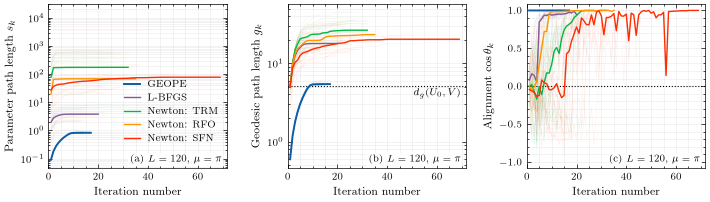

In [5]:
def path_lengths(run):
    """Cumulative parameter-space path length $s_k$ at every iterate, zero at the start."""
    steps = np.linalg.norm(np.diff(run["phi"], axis=0), axis=1)
    return np.concatenate([[0.0], np.cumsum(steps)])


def geodesic_lengths(distances):
    """Cumulative geodesic distance $g_k$ from one run's per-step distances, zero at the start."""
    return np.concatenate([[0.0], np.cumsum(distances)])


def median_of_running(curves):
    """Elementwise median over the runs that still have a value at each index: no padding."""
    longest = max(c.size for c in curves)
    padded = np.full((len(curves), longest), np.nan)
    for row, c in zip(padded, curves):
        row[: c.size] = c
    return np.nanmedian(padded, axis=0)


def draw_lengths(ax, curves_by_method):
    """Cumulative length against iteration, medians over faint individual runs, from step 1."""
    for method, curves in curves_by_method.items():
        for y in curves:
            ax.semilogy(np.arange(1, y.size), y[1:], color=COLOURS[STYLE_KEYS[method]], **FAINT)
    for method, curves in curves_by_method.items():
        y = median_over_runs(curves)
        ax.semilogy(np.arange(1, y.size), y[1:], **method_style(STYLE_KEYS[method]))
    ax.set_xlabel("Iteration number")
    ax.grid(alpha=0.25, which="both", lw=0.4)


def draw_alignment(ax, curves_by_method):
    """cos theta of step k at iteration k, medians over the seeds still running."""
    for method, curves in curves_by_method.items():
        for y in curves:
            ax.plot(np.arange(1, y.size + 1), y, color=COLOURS[STYLE_KEYS[method]], **FAINT)
    for method, curves in curves_by_method.items():
        y = median_of_running(curves)
        ax.plot(np.arange(1, y.size + 1), y, **method_style(STYLE_KEYS[method]))
    ax.axhline(0.0, color="black", ls=":", lw=0.8, zorder=2)
    ax.set_ylim(-1.08, 1.08)
    ax.set_xlabel("Iteration number")
    ax.grid(alpha=0.25, which="both", lw=0.4)


cases = [(spread, steps) for spread in SPREADS for steps in CASES]
fig, axes = plt.subplots(
    len(cases), 3, figsize=(TWO_COLUMN, 2.1 * len(cases)), sharex="row", squeeze=False,
)
letters = iter("abcdefghijkl")
for (ax_param, ax_group, ax_align), (spread, steps) in zip(axes, cases):
    runs_by_method = {m: traj[(spread, steps, m)] for m in METHODS}
    draw_lengths(
        ax_param, {m: [path_lengths(r) for r in runs] for m, runs in runs_by_method.items()}
    )
    draw_lengths(
        ax_group, {m: [geodesic_lengths(d) for d in geo[(spread, steps, m)]] for m in METHODS}
    )
    draw_alignment(ax_align, {m: align[(spread, steps, m)] for m in METHODS})
    floor = table.query("spread == @spread and L == @steps").geo_start_to_target.median()
    ax_group.axhline(floor, color="black", ls=":", lw=0.8, zorder=2)
    ax_group.annotate(
        r"$d_g(U_0, V)$", (0.97, floor), xycoords=("axes fraction", "data"),
        ha="right", va="top", fontsize=ANNOTATION_SIZE, xytext=(0, -1.5), textcoords="offset points",
    )
    longest = max(r["phi"].shape[0] - 1 for runs in runs_by_method.values() for r in runs)
    ax_param.set_xlim(0, 1.04 * longest)
    ax_param.set_ylabel(r"Parameter path length $s_k$")
    ax_group.set_ylabel(r"Geodesic path length $g_k$")
    ax_align.set_ylabel(r"Alignment $\cos\theta_k$")
    for ax in (ax_param, ax_group, ax_align):
        ax.text(
            0.97, 0.04, rf"({next(letters)}) $L={steps}$, $\mu={SPREAD_LABELS[spread]}$",
            transform=ax.transAxes, ha="right", fontsize=ANNOTATION_SIZE, zorder=5,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2),
        )
# Lower right of the first panel, above the case label: GEOPE and L-BFGS have landed by
# iteration 20, so that corner is empty, while the Newton rules occupy the top from step 1.
axes[0, 0].legend(loc="lower right", bbox_to_anchor=(1.0, 0.1), frameon=False,
                  handlelength=1.6)
fig.subplots_adjust(left=0.065, right=0.99, top=0.98, bottom=0.2, wspace=0.34)
slug = "_".join(f"L{steps}_{spread_slug(spread)}" for spread, steps in cases)
print(save_figure(fig, f"extra_fig6_path_lengths_alignment_{slug}"))
plt.show()